# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rio Alfian
- **Email:** 1247050145@student.uinsgd.ac.id
- **ID Dicoding:** rio_alfianac1o

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Seberapa besar persentase penurunan rata-rata penyewaan sepeda harian (`cnt`) akibat perubahan musim (khususnya musim semi/Spring dibandingkan musim puncak/Fall) dan kondisi cuaca buruk (`Light Snow/Rain` dibandingkan cuaca cerah) di Washington D.C. selama periode tahun 2011–2012, serta bagaimana alokasi optimal jumlah armada sepeda aktif pada kondisi tersebut?
- **Pertanyaan 2:** Pada jam berapa terjadi beban puncak (peak hours) penyewaan sepeda per jam pada hari kerja (`workingday = 1`) dibandingkan akhir pekan/hari libur (`workingday = 0`), serta berapa persen lonjakan kontribusi segmen pengguna `casual` dibandingkan `registered` sepanjang periode 2011–2012 untuk mengoptimalkan jadwal redistribusi sepeda dan promosi langganan?

## Import Semua Packages/Library yang Digunakan

In [7]:
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 120

# Membuat folder data/ dan dashboard/ otomatis di Google Colab agar struktur rapi
os.makedirs("data", exist_ok=True)
os.makedirs("dashboard", exist_ok=True)

# Memindahkan day.csv & hour.csv ke dalam folder data/ jika di-upload di luar folder
if os.path.exists("day.csv") and not os.path.exists("data/day.csv"):
    shutil.copy("day.csv", "data/day.csv")
if os.path.exists("hour.csv") and not os.path.exists("data/hour.csv"):
    shutil.copy("hour.csv", "data/hour.csv")

print("Library berhasil dimuat dan struktur folder siap!")

Library berhasil dimuat dan struktur folder siap!


In [8]:
import os
import shutil

# Memastikan folder data/ ada
os.makedirs("data", exist_ok=True)

# Menyalin file dari /content/ ke /content/data/ jika belum dipindahkan
if os.path.exists("day.csv") and not os.path.exists("data/day.csv"):
    shutil.copy("day.csv", "data/day.csv")
    print("day.csv berhasil disalin ke data/day.csv")

if os.path.exists("hour.csv") and not os.path.exists("data/hour.csv"):
    shutil.copy("hour.csv", "data/hour.csv")
    print("hour.csv berhasil disalin ke data/hour.csv")


## Data Wrangling

### Gathering Data

#### Load Tabel `day.csv` dan `hour.csv`

In [9]:
day_df = pd.read_csv("data/day.csv")
hour_df = pd.read_csv("data/hour.csv")

print(f"Dimensi day_df  : {day_df.shape[0]} baris, {day_df.shape[1]} kolom")
print(f"Dimensi hour_df : {hour_df.shape[0]} baris, {hour_df.shape[1]} kolom")
print("\n3 Baris Pertama day_df:")
print(day_df.head(3).to_string())
print("\n3 Baris Pertama hour_df:")
print(hour_df.head(3).to_string())

Dimensi day_df  : 731 baris, 16 kolom
Dimensi hour_df : 17379 baris, 17 kolom

3 Baris Pertama day_df:
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  weathersit      temp     atemp       hum  windspeed  casual  registered   cnt
0        1  2011-01-01       1   0     1        0        6           0           2  0.344167  0.363625  0.805833   0.160446     331         654   985
1        2  2011-01-02       1   0     1        0        0           0           2  0.363478  0.353739  0.696087   0.248539     131         670   801
2        3  2011-01-03       1   0     1        0        1           1           1  0.196364  0.189405  0.437273   0.248309     120        1229  1349

3 Baris Pertama hour_df:
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  weathersit  temp   atemp   hum  windspeed  casual  registered  cnt
0        1  2011-01-01       1   0     1   0        0        6           0           1  0.24  0.2879  0.81        0.0       3   

**Insight:**
- Dataset `day_df` memuat **731 baris dan 16 kolom** yang merepresentasikan total penyewaan sepeda harian selama 2 tahun (365 hari pada tahun 2011 dan 366 hari pada tahun kabisat 2012).
- Dataset `hour_df` memuat **17.379 baris dan 17 kolom** yang merepresentasikan penyewaan sepeda secara mendetail pada setiap jam operasional (`hr` dari 0 hingga 23).

### Assessing Data

#### Identifying Missing Value, Duplicate Data, Invalid Data Type, Inaccurate Value & Outlier

In [10]:
print("=== 1. PEMERIKSAAN MISSING VALUES & DUPLIKASI ===")
print("Missing values day_df :", day_df.isna().sum().sum())
print("Missing values hour_df:", hour_df.isna().sum().sum())
print("Duplikasi day_df      :", day_df.duplicated().sum())
print("Duplikasi hour_df     :", hour_df.duplicated().sum())
print("Tipe data dteday      :", day_df['dteday'].dtype)

print("\n=== 2. DETEKSI INACCURATE VALUE (KELEMBABAN 0% SAAT HUJAN) ===")
print(day_df[day_df['hum'] == 0][['instant', 'dteday', 'season', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']].to_string())
print(f"Jumlah jam dengan hum == 0 di hour_df: {(hour_df['hum'] == 0).sum()} baris (pada 2011-03-10)")

print("\n=== 3. DETEKSI OUTLIER DENGAN METODE IQR (DAY_DF) ===")
for col in ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']:
    q25, q75 = np.percentile(day_df[col], 25), np.percentile(day_df[col], 75)
    iqr = q75 - q25
    lower, upper = q25 - 1.5 * iqr, q75 + 1.5 * iqr
    outliers = day_df[(day_df[col] < lower) | (day_df[col] > upper)]
    print(f"- Kolom '{col:10s}': {len(outliers):2d} outlier (Batas bawah={lower:.4f}, Batas atas={upper:.4f})")

=== 1. PEMERIKSAAN MISSING VALUES & DUPLIKASI ===
Missing values day_df : 0
Missing values hour_df: 0
Duplikasi day_df      : 0
Duplikasi hour_df     : 0
Tipe data dteday      : object

=== 2. DETEKSI INACCURATE VALUE (KELEMBABAN 0% SAAT HUJAN) ===
    instant      dteday  season  weathersit      temp  hum  windspeed  cnt
68       69  2011-03-10       1           3  0.389091  0.0   0.261877  623
Jumlah jam dengan hum == 0 di hour_df: 22 baris (pada 2011-03-10)

=== 3. DETEKSI OUTLIER DENGAN METODE IQR (DAY_DF) ===
- Kolom 'temp      ':  0 outlier (Batas bawah=-0.1404, Batas atas=1.1329)
- Kolom 'atemp     ':  0 outlier (Batas bawah=-0.0683, Batas atas=1.0147)
- Kolom 'hum       ':  2 outlier (Batas bawah=0.2047, Batas atas=1.0455)
- Kolom 'windspeed ': 13 outlier (Batas bawah=-0.0124, Batas atas=0.3806)
- Kolom 'casual    ': 44 outlier (Batas bawah=-855.2500, Batas atas=2266.7500)
- Kolom 'registered':  0 outlier (Batas bawah=-922.2500, Batas atas=8195.7500)
- Kolom 'cnt       ':  0 ou

**Steps to Take:**
- Mengonversi tipe data kolom `dteday` dari `object` (string) menjadi `datetime64[ns]`.
- Mengimputasi *inaccurate value* `hum == 0.0` pada tanggal `2011-03-10` dengan nilai rata-rata (*mean*) kelembaban pada hari/jam dengan kondisi cuaca serupa (`weathersit == 3` dan `season == 1`).
- Memetakan kode angka kategorikal (`season`, `yr`, `weathersit`, `weekday`, `workingday`) menjadi label deskriptif serta mengembalikan nilai normalisasi cuaca (`temp`, `atemp`, `hum`, `windspeed`) ke satuan fisik aslinya (°C, %, km/jam).

**Insight:**
- Tidak ditemukan *missing values* maupun data duplikat pada `day_df` dan `hour_df`.
- Ditemukan **2 masalah utama kualitas data**: (1) Tipe data `dteday` masih `object` dan atribut kategorikal masih berupa angka kode, serta (2) Terdapat **Inaccurate Value** berupa nilai kelembaban `hum = 0.0` (0%) pada tanggal `2011-03-10` saat cuaca sedang hujan ringan (`weathersit = 3`), yang juga terdeteksi sebagai *outlier* bawah pada metode IQR.

### Cleaning Data

#### Fixing Data Types, Imputing Inaccurate Humidity (`hum == 0`), and Denormalizing Features

In [11]:
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# 1. Konversi dteday menjadi datetime
day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])
hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])

# 2. Imputasi inaccurate value hum == 0 pada 2011-03-10
mean_hum_day = day_clean[(day_clean['weathersit'] == 3) & (day_clean['season'] == 1) & (day_clean['hum'] > 0)]['hum'].mean()
mean_hum_hour = hour_clean[(hour_clean['weathersit'] == 3) & (hour_clean['season'] == 1) & (hour_clean['hum'] > 0)]['hum'].mean()

day_clean.loc[day_clean['hum'] == 0, 'hum'] = mean_hum_day
hour_clean.loc[hour_clean['hum'] == 0, 'hum'] = mean_hum_hour

# 3. Mapping label kategorikal & denormalisasi metrik cuaca
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map = {0: 2011, 1: 2012}
weather_map = {1: 'Clear/Partly Cloudy', 2: 'Mist/Cloudy', 3: 'Light Snow/Rain', 4: 'Heavy Rain/Snow'}
weekday_map = {0: 'Minggu', 1: 'Senin', 2: 'Selasa', 3: 'Rabu', 4: 'Kamis', 5: 'Jumat', 6: 'Sabtu'}
workingday_map = {0: 'Akhir Pekan / Libur', 1: 'Hari Kerja'}

for df in [day_clean, hour_clean]:
    df['season_label'] = df['season'].map(season_map)
    df['year'] = df['yr'].map(yr_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['weekday_label'] = df['weekday'].map(weekday_map)
    df['day_type'] = df['workingday'].map(workingday_map)
    df['temp_c'] = df['temp'] * 41.0
    df['atemp_c'] = df['atemp'] * 50.0
    df['hum_pct'] = df['hum'] * 100.0
    df['windspeed_kmh'] = df['windspeed'] * 67.0

print(f"Imputasi selesai! Nilai hum == 0 diganti menjadi: {mean_hum_day:.4f} (day) dan {mean_hum_hour:.4f} (hour)")
print("Verifikasi jumlah baris dengan hum == 0 setelah cleaning:", (day_clean['hum'] == 0).sum())

Imputasi selesai! Nilai hum == 0 diganti menjadi: 0.8057 (day) dan 0.8512 (hour)
Verifikasi jumlah baris dengan hum == 0 setelah cleaning: 0


**Insight:**
- Nilai kelembaban tidak akurat (`hum = 0.0`) pada tanggal `2011-03-10` telah berhasil diimputasi menjadi **0,8057 (80,57%)** pada `day_clean` dan **0,8512 (85,12%)** pada `hour_clean`.
- Seluruh kolom tanggal dan variabel kategorikal kini telah bersih serta memiliki satuan fisik asli yang siap dianalisis.

## Exploratory Data Analysis (EDA)

### Explore Statistik Penyewaan Berdasarkan Tahun, Musim, Cuaca, dan Jam Operasional

In [12]:
print("=== 1. STATISTIK PERTUMBUHAN TAHUNAN (2011 VS 2012) ===")
print(day_clean.groupby('year')[['casual', 'registered', 'cnt']].agg(['count', 'sum', 'mean', 'median', 'std']).to_string())

print("\n=== 2. STATISTIK PENYEWAAN HARIAN PER MUSIM (SEASON) ===")
print(day_clean.groupby('season_label')[['casual', 'registered', 'cnt']].agg(['count', 'sum', 'mean', 'median', 'std', 'min', 'max']).to_string())

print("\n=== 3. STATISTIK PENYEWAAN HARIAN BERDASARKAN CUACA ===")
print(day_clean.groupby('weather_label')[['casual', 'registered', 'cnt']].agg(['count', 'sum', 'mean', 'median', 'std', 'min', 'max']).to_string())

print("\n=== 4. STATISTIK HARI KERJA VS AKHIR PEKAN / LIBUR ===")
print(day_clean.groupby('day_type')[['casual', 'registered', 'cnt']].agg(['count', 'mean', 'median', 'std']).to_string())

hourly_summary = hour_clean.groupby(['day_type', 'hr'])[['casual', 'registered', 'cnt']].mean().reset_index()
print("\n=== 5. TOP 3 JAM TERSIBUK PADA HARI KERJA ===")
print(hourly_summary[hourly_summary['day_type'] == 'Hari Kerja'].sort_values(by='cnt', ascending=False).head(3).to_string(index=False))

print("\n=== 6. TOP 3 JAM TERSIBUK PADA AKHIR PEKAN / LIBUR ===")
print(hourly_summary[hourly_summary['day_type'] == 'Akhir Pekan / Libur'].sort_values(by='cnt', ascending=False).head(3).to_string(index=False))

=== 1. STATISTIK PERTUMBUHAN TAHUNAN (2011 VS 2012) ===
     casual                                         registered                                              cnt                                           
      count     sum         mean median         std      count      sum         mean  median          std count      sum         mean  median          std
year                                                                                                                                                      
2011    365  247252   677.402740  614.0  556.269121        365   995851  2728.358904  2915.0  1060.110413   365  1243103  3405.761644  3740.0  1378.753666
2012    366  372765  1018.483607  904.5  758.989897        366  1676811  4581.450820  4776.5  1424.331846   366  2049576  5599.934426  5927.0  1788.667868

=== 2. STATISTIK PENYEWAAN HARIAN PER MUSIM (SEASON) ===
             casual                                                     registered                             

**Insight:**
- Total penyewaan sepeda tumbuh **64,88% YoY**, dari **1.243.103 unit** di 2011 menjadi **2.049.576 unit** di 2012.
- Rata-rata penyewaan harian pada **Musim Semi (Spring)** adalah **2.604,13 unit/hari**, lebih rendah **53,86%** dibandingkan **Musim Gugur (Fall)** yang mencapai **5.644,30 unit/hari**.
- Cuaca **Light Snow/Rain** menurunkan rata-rata penyewaan harian sebesar **63,02%** (**1.803,29 unit/hari**) dibandingkan cuaca **Clear/Partly Cloudy** (**4.876,79 unit/hari**).
- Hari Kerja memiliki puncak jam komuter pada pukul **17:00 (525,29 unit/jam)** dan **08:00 (477,01 unit/jam)**, sedangkan Akhir Pekan/Libur memuncak pada pukul **13:00 siang (372,73 unit/jam)** dengan lonjakan penyewa `casual` sebesar **126,05%**.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_588/2019260882.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=season_means, x='season_label', y='cnt', palette=colors_season, ax=axes[0])
/tmp/ipykernel_588/2019260882.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=weather_means, x='weather_label', y='cnt', palette=colors_weather, ax=axes[1])


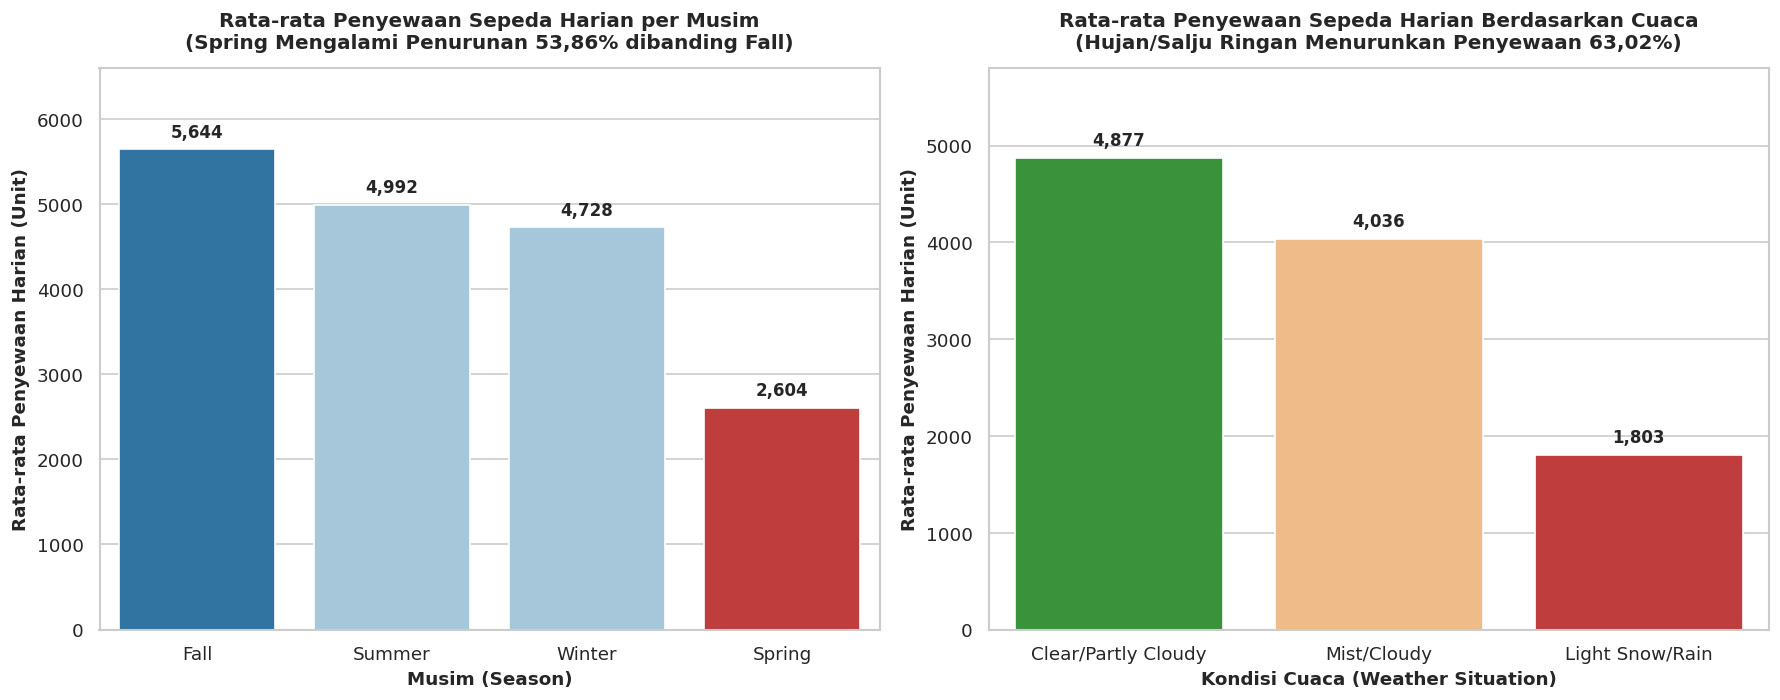

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

season_order = ['Fall', 'Summer', 'Winter', 'Spring']
season_means = day_clean.groupby('season_label')['cnt'].mean().reindex(season_order).reset_index()
colors_season = ['#1f77b4', '#9ecae1', '#9ecae1', '#d62728']
sns.barplot(data=season_means, x='season_label', y='cnt', palette=colors_season, ax=axes[0])
axes[0].set_title('Rata-rata Penyewaan Sepeda Harian per Musim\n(Spring Mengalami Penurunan 53,86% dibanding Fall)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Musim (Season)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[0].set_ylim(0, 6600)
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_means = day_clean.groupby('weather_label')['cnt'].mean().reindex(weather_order).reset_index()
colors_weather = ['#2ca02c', '#ffbb78', '#d62728']
sns.barplot(data=weather_means, x='weather_label', y='cnt', palette=colors_weather, ax=axes[1])
axes[1].set_title('Rata-rata Penyewaan Sepeda Harian Berdasarkan Cuaca\n(Hujan/Salju Ringan Menurunkan Penyewaan 63,02%)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kondisi Cuaca (Weather Situation)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 5800)
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

### Pertanyaan 2:

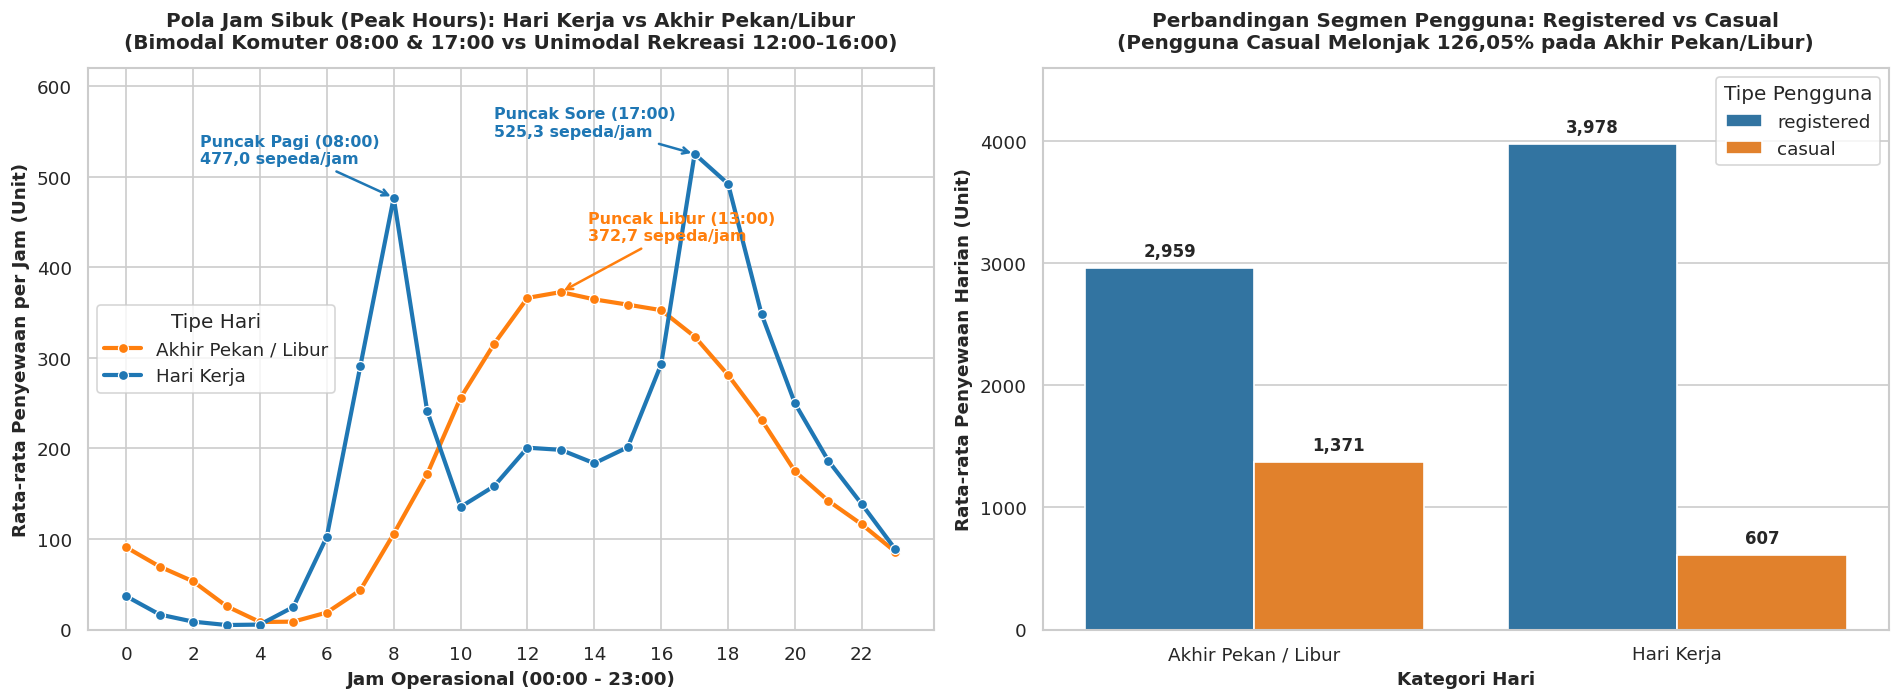

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(
    data=hourly_summary, x='hr', y='cnt', hue='day_type',
    palette={'Hari Kerja': '#1f77b4', 'Akhir Pekan / Libur': '#ff7f0e'},
    marker='o', linewidth=2.5, ax=axes[0]
)
axes[0].set_title('Pola Jam Sibuk (Peak Hours): Hari Kerja vs Akhir Pekan/Libur\n(Bimodal Komuter 08:00 & 17:00 vs Unimodal Rekreasi 12:00-16:00)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Jam Operasional (00:00 - 23:00)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=11, fontweight='bold')
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_ylim(0, 620)
axes[0].annotate('Puncak Pagi (08:00)\n477,0 sepeda/jam', xy=(8, 477), xytext=(2.2, 515),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4', fontsize=9.5)
axes[0].annotate('Puncak Sore (17:00)\n525,3 sepeda/jam', xy=(17, 525.3), xytext=(11.0, 545),
                 arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=1.5), fontweight='bold', color='#1f77b4', fontsize=9.5)
axes[0].annotate('Puncak Libur (13:00)\n372,7 sepeda/jam', xy=(13, 372.7), xytext=(13.8, 430),
                 arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=1.5), fontweight='bold', color='#ff7f0e', fontsize=9.5)
axes[0].legend(title='Tipe Hari', frameon=True)

seg_day = day_clean.groupby('day_type')[['registered', 'casual']].mean().reset_index()
seg_melted = seg_day.melt(id_vars='day_type', value_vars=['registered', 'casual'], var_name='Tipe Pengguna', value_name='Rata-rata Harian')
sns.barplot(data=seg_melted, x='day_type', y='Rata-rata Harian', hue='Tipe Pengguna', palette={'registered': '#1f77b4', 'casual': '#ff7f0e'}, ax=axes[1])
axes[1].set_title('Perbandingan Segmen Pengguna: Registered vs Casual\n(Pengguna Casual Melonjak 126,05% pada Akhir Pekan/Libur)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kategori Hari', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 4600)
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                         ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

**Insight:**
- Visualisasi Pertanyaan 1 membuktikan bahwa musim semi (*Spring*) dan cuaca hujan/salju ringan (*Light Snow/Rain*) menjadi titik kritis penurunan permintaan masing-masing sebesar **53,86%** dan **63,02%**.
- Visualisasi Pertanyaan 2 memperlihatkan pola **bimodal** pada Hari Kerja (puncak komuter pukul **08:00** dan **17:00**) serta pola **unimodal** pada Akhir Pekan/Libur (puncak rekreasi pukul **12:00–16:00**) dengan lonjakan segmen `casual` sebesar **126,05%**.

## Analisis Lanjutan (Opsional)
Pada tahap ini diterapkan teknik **Clustering (Tanpa Algoritma Machine Learning)** menggunakan dua metode:
1. **Manual Grouping (`time_cluster`):** Mengelompokkan 24 jam operasional ke dalam 5 klaster waktu untuk memetakan kebutuhan *rebalancing* armada.
2. **Binning (`temp_bin`):** Mengelompokkan suhu udara aktual (`temp_c`) ke dalam 3 interval kenyamanan termal (`Dingin <15°C`, `Nyaman/Ideal 15°C–25°C`, dan `Panas >25°C`).

/tmp/ipykernel_588/2450316011.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tc_df, y='time_cluster', x='cnt', palette=colors_tc, ax=axes[0])
/tmp/ipykernel_588/2450316011.py:44: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tb_df, x='temp_bin', y='cnt', palette=colors_tb, ax=axes[1])


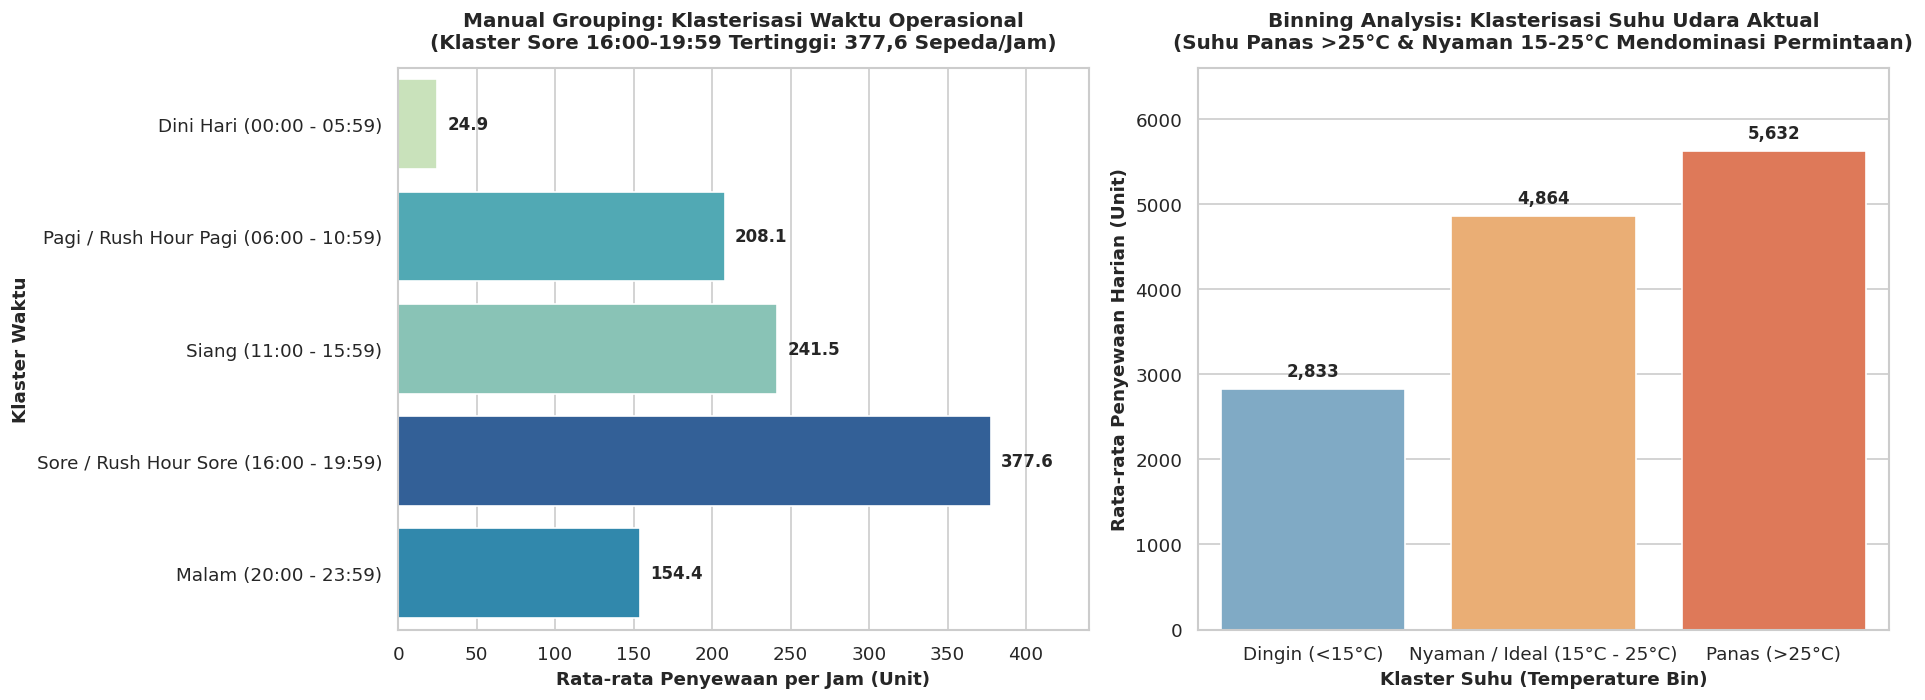

In [15]:
def categorize_time_of_day(hr):
    if 0 <= hr <= 5:
        return 'Dini Hari (00:00 - 05:59)'
    elif 6 <= hr <= 10:
        return 'Pagi / Rush Hour Pagi (06:00 - 10:59)'
    elif 11 <= hr <= 15:
        return 'Siang (11:00 - 15:59)'
    elif 16 <= hr <= 19:
        return 'Sore / Rush Hour Sore (16:00 - 19:59)'
    else:
        return 'Malam (20:00 - 23:59)'

hour_clean['time_cluster'] = hour_clean['hr'].apply(categorize_time_of_day)
time_order = [
    'Dini Hari (00:00 - 05:59)',
    'Pagi / Rush Hour Pagi (06:00 - 10:59)',
    'Siang (11:00 - 15:59)',
    'Sore / Rush Hour Sore (16:00 - 19:59)',
    'Malam (20:00 - 23:59)'
]

day_clean['temp_bin'] = pd.cut(
    day_clean['temp_c'],
    bins=[0, 15, 25, 41],
    labels=['Dingin (<15°C)', 'Nyaman / Ideal (15°C - 25°C)', 'Panas (>25°C)']
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

tc_df = hour_clean.groupby('time_cluster')['cnt'].mean().reindex(time_order).reset_index()
colors_tc = ['#c7e9b4', '#41b6c4', '#7fcdbb', '#225ea8', '#1d91c0']
sns.barplot(data=tc_df, y='time_cluster', x='cnt', palette=colors_tc, ax=axes[0])
axes[0].set_title('Manual Grouping: Klasterisasi Waktu Operasional\n(Klaster Sore 16:00-19:59 Tertinggi: 377,6 Sepeda/Jam)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Rata-rata Penyewaan per Jam (Unit)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Klaster Waktu', fontsize=11, fontweight='bold')
axes[0].set_xlim(0, 440)
for p in axes[0].patches:
    width = p.get_width()
    axes[0].annotate(f'{width:,.1f}', (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center', fontsize=10, fontweight='bold', xytext=(6, 0), textcoords='offset points')

tb_df = day_clean.groupby('temp_bin', observed=False)['cnt'].mean().reset_index()
colors_tb = ['#74add1', '#fdae61', '#f46d43']
sns.barplot(data=tb_df, x='temp_bin', y='cnt', palette=colors_tb, ax=axes[1])
axes[1].set_title('Binning Analysis: Klasterisasi Suhu Udara Aktual\n(Suhu Panas >25°C & Nyaman 15-25°C Mendominasi Permintaan)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Klaster Suhu (Temperature Bin)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Rata-rata Penyewaan Harian (Unit)', fontsize=11, fontweight='bold')
axes[1].set_ylim(0, 6600)
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:,.0f}', (p.get_x() + p.get_width() / 2., height),
                     ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

hour_clean.to_csv("dashboard/main_data.csv", index=False)

**Insight:**
- Klaster waktu **Sore (`16:00–19:59`)** mencatat rata-rata penyewaan tertinggi sebesar **377,6 sepeda/jam**, sedangkan klaster **Dini Hari (`00:00–05:59`)** paling rendah yaitu **24,9 sepeda/jam** sehingga ideal dijadikan waktu operasional *rebalancing* stasiun.
- Berdasarkan *Binning* suhu udara, klaster suhu **Panas (`>25°C`)** dan **Nyaman (`15°C–25°C`)** mendominasi rata-rata penyewaan harian (**5.632 unit/hari** dan **4.864 unit/hari**), sedangkan suhu **Dingin (`<15°C`)** menurunkan permintaan menjadi **2.833 unit/hari**.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Musim dan kondisi cuaca berdampak signifikan terhadap penyewaan sepeda sepanjang 2011–2012. Rata-rata penyewaan harian tertinggi terjadi pada **Musim Gugur (Fall)** sebesar **5.644,30 unit/hari** dan terendah pada **Musim Semi (Spring)** sebesar **2.604,13 unit/hari** (turun **53,86%**). Kondisi cuaca hujan/salju ringan (`Light Snow/Rain`) menurunkan rata-rata penyewaan harian sebesar **63,02%** (**1.803,29 unit/hari**) dibandingkan cuaca cerah (**4.876,79 unit/hari**).
- **Conclusion pertanyaan 2:** Pada **Hari Kerja (`workingday = 1`)**, beban puncak membentuk pola **bimodal** pada pukul **08:00 pagi (477,0 sepeda/jam)** dan pukul **17:00 sore (525,3 sepeda/jam)** yang didominasi komuter `registered` (**3.978,25 unit/hari**). Sebaliknya, pada **Akhir Pekan/Hari Libur (`workingday = 0`)**, beban puncak membentuk pola **unimodal** pada pukul **12:00–16:00 siang (puncak pukul 13:00 sebesar 372,7 sepeda/jam)** dengan lonjakan pengguna `casual` sebesar **126,05%** (dari **606,57** menjadi **1.371,13 unit/hari**).

**Rekomendasi Action Item:**
- **Penjadwalan Preventive Maintenance & Kuota Armada Musiman:** Menjadwalkan perawatan besar (*overhaul* armada sepeda) pada **Musim Semi (Spring)** dan hari bersuhu **`<15°C`**, serta menarik sementara **30%–40% armada aktif** ke gudang terlindung saat prakiraan cuaca menunjukkan hujan/salju (`weathersit >= 3`).
- **Jadwal Rebalancing Stasiun pada Klaster Waktu Lengang:** Mengoperasikan truk redistribusi sepeda pada klaster **Dini Hari (`04:00–05:59`)** ke stasiun area permukiman sebelum jam sibuk pagi (**08:00**), serta pukul **14:00–15:30** ke stasiun kawasan perkantoran/kampus sebelum jam sibuk sore (**17:00**).
- **Program Promosi Weekend Leisure Pass:** Meluncurkan paket *bundling* akhir pekan disertai kupon diskon pendaftaran *annual membership* untuk mengonversi tingginya pengguna `casual` pada hari Sabtu–Minggu menjadi pelanggan `registered`.